In [11]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras import regularizers
from tensorflow.keras.models import Model, load_model
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import seaborn as sns
sns.set_style('darkgrid')
from sklearn.metrics import confusion_matrix, classification_report
from IPython.core.display import display, HTML


In [12]:
import os
import shutil
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/input/datasets/shuvosingh/brain-tumor-mri-dataset/Brain_Tumor_MRI_Dataset_Final"
CLEAN_DIR = "/kaggle/working/prepared_dataset_clean"
SEED = 42
IMG_EXTS = (".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff")

paths, labels = [], []
for root, dirs, files in os.walk(DATA_DIR):
    dirs.sort()
    for f in sorted(files):
        if f.lower().endswith(IMG_EXTS):
            paths.append(os.path.join(root, f))
            labels.append(os.path.basename(root))

paths = np.array(paths)
labels = np.array(labels)
classes = sorted(set(labels))
class_count = len(classes)
print("Classes found:", classes)
print("Total images:", len(paths))

tr_p, tmp_p, tr_l, tmp_l = train_test_split(paths, labels, test_size=0.20, stratify=labels, random_state=SEED)
va_p, te_p, va_l, te_l = train_test_split(tmp_p, tmp_l, test_size=0.50, stratify=tmp_l, random_state=SEED)

if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

rows = {"train": [], "val": [], "test": []}
for split, ps, ls in (("train", tr_p, tr_l), ("val", va_p, va_l), ("test", te_p, te_l)):
    for i, (p, c) in enumerate(zip(ps, ls)):
        dst_dir = os.path.join(CLEAN_DIR, split, c)
        os.makedirs(dst_dir, exist_ok=True)
        dst = os.path.join(dst_dir, f"{i}_{os.path.basename(p)}")
        shutil.copy2(p, dst)
        rows[split].append((dst, c))

n = len(paths)
for split in ("train", "val", "test"):
    cnt = Counter(c for _, c in rows[split])
    print(f"{split}: {len(rows[split])} ({len(rows[split]) / n * 100:.1f}%)", dict(sorted(cnt.items())))

train_df = pd.DataFrame(rows["train"], columns=["filepaths", "labels"])
valid_df = pd.DataFrame(rows["val"],   columns=["filepaths", "labels"])
test_df  = pd.DataFrame(rows["test"],  columns=["filepaths", "labels"])

print('train size: ', len(train_df), '  valid size: ', len(valid_df), '   test size: ', len(test_df))
length = len(test_df)

Classes found: [np.str_('glioma'), np.str_('meningioma'), np.str_('no_tumor'), np.str_('pituitary')]
Total images: 5941
train: 4752 (80.0%) {np.str_('glioma'): 1753, np.str_('meningioma'): 1182, np.str_('no_tumor'): 629, np.str_('pituitary'): 1188}
val: 594 (10.0%) {np.str_('glioma'): 219, np.str_('meningioma'): 148, np.str_('no_tumor'): 79, np.str_('pituitary'): 148}
test: 595 (10.0%) {np.str_('glioma'): 219, np.str_('meningioma'): 148, np.str_('no_tumor'): 79, np.str_('pituitary'): 149}
train size:  4752   valid size:  594    test size:  595


In [13]:
balance = train_df['labels'].value_counts()
print(balance)


labels
glioma        1753
pituitary     1188
meningioma    1182
no_tumor       629
Name: count, dtype: int64


In [14]:
print('train size: ', len(train_df), '  valid size: ', len(valid_df), '   test size: ', len(test_df))


train size:  4752   valid size:  594    test size:  595


In [15]:
batch_size=16
def scalar(x):
    return x/127.5-1 # rescales pixels to range -1 to +1
trgen=tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=scalar, horizontal_flip=True)
train_gen=trgen.flow_from_dataframe(train_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=batch_size, shuffle=True, seed=123)
tvgen=tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=scalar)
valid_gen=tvgen.flow_from_dataframe(valid_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=batch_size, shuffle=False)
# determine test generator batch size and steps to go through the test set exactly once for predictions
test_batch_size=sorted([int(length/n) for n in range(1,length+1) if length % n ==0 and length/n<=batch_size],reverse=True)[0]
test_steps=int(length/test_batch_size)
test_gen=tvgen.flow_from_dataframe(test_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=test_batch_size, shuffle=False)
test_labels=test_gen.labels

Found 4752 validated image filenames belonging to 4 classes.
Found 594 validated image filenames belonging to 4 classes.
Found 595 validated image filenames belonging to 4 classes.


In [16]:
def show_training_samples(gen):
    class_dict=gen.class_indices
    new_dict={}
    # make a new dictionary with keys and values reversed
    for key, value in class_dict.items(): # dictionary is now {numeric class label: string of class_name}
        new_dict[value]=key
    images,labels=next(gen) # get a sample batch from the generator
    plt.figure(figsize=(15, 18)) # Adjusted figure size for better display
    length=len(labels)
    if length<30:   #show maximum of 30 images
        r=length
    else:
        r=30
    for i in range(r):
        plt.subplot(6, 5, i + 1) # Changed grid to 6x5 to accommodate 30 subplots
        image=(images[i]+1 )/2 # scale images between 0 and 1 becaue pre-processor set them between -1 and +1
        plt.imshow(image)
        index=np.argmax(labels[i])
        class_name=new_dict[index]
        plt.title(class_name, color='blue', fontsize=16)
        plt.axis('off')
    plt.show()

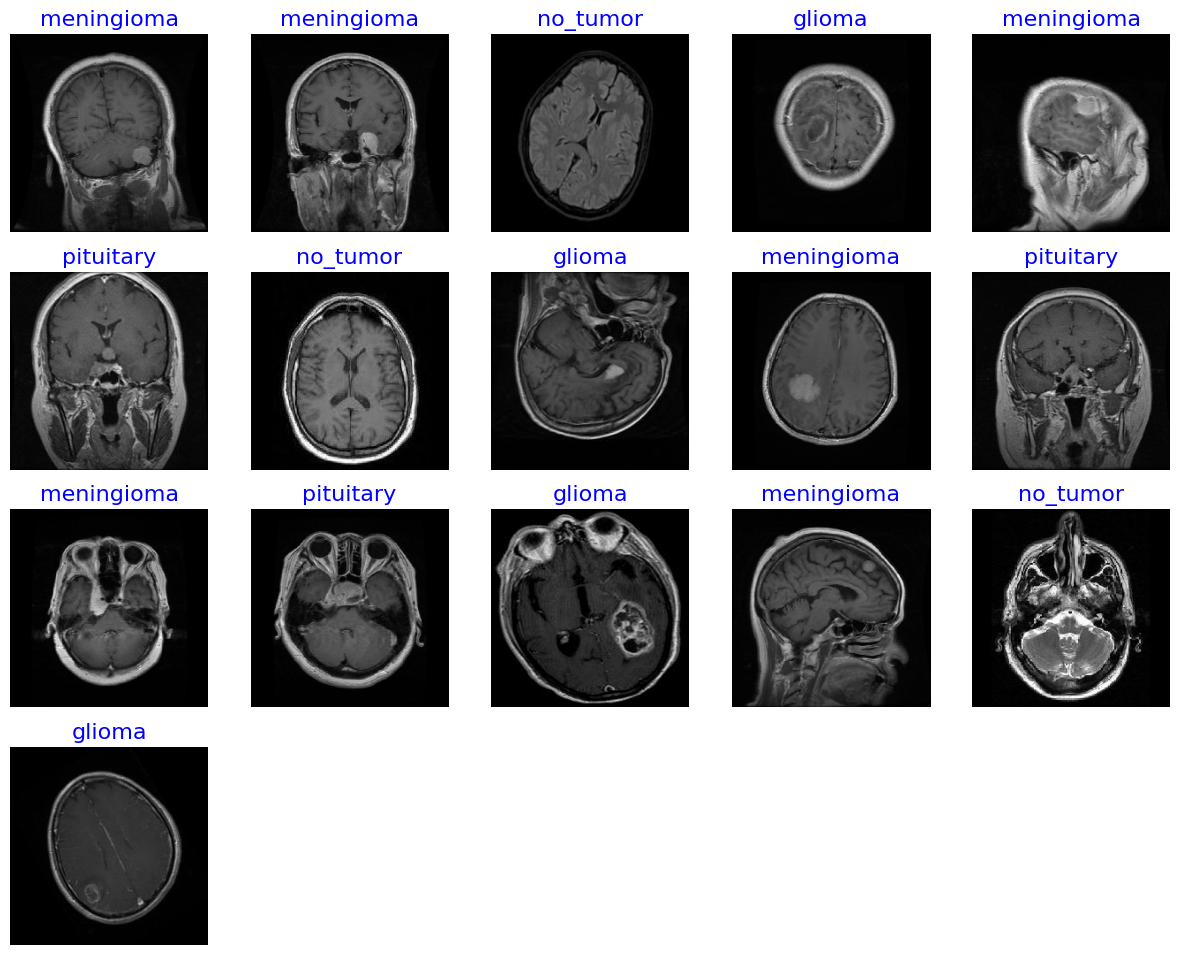

In [17]:
show_training_samples(train_gen)

In [18]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet169
from tensorflow.keras.optimizers import Adam

input_shape = (224, 224, 3)
class_count = len(classes)

print("Number of classes:", class_count)
print("Classes:", classes)

base_model = DenseNet169(
    weights='imagenet',
    include_top=False,
    input_shape=input_shape
)

base_model.trainable = False

inputs = layers.Input(shape=input_shape)
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(class_count, activation='softmax')(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nDenseNet169 Model Summary:")
model.summary()

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nDenseNet169 Fine-tuning Summary:")
model.summary()

Number of classes: 4
Classes: [np.str_('glioma'), np.str_('meningioma'), np.str_('no_tumor'), np.str_('pituitary')]

DenseNet169 Model Summary:


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         6,660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,649,540 (48.25 MB)

 Trainable params: 6,660 (26.02 KB)

...

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         6,660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,649,540 (48.25 MB)

 Trainable params: 982,148 (3.75 MB)

 Non-trainable params: 11,667,392 (44.51 MB)

In [19]:
'''
# Import necessary libraries
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet169
from tensorflow.keras.optimizers import Adam

# Define input shape
input_shape = (224, 224, 3)

# Automatically detect number of classes
class_count = len(train_gen.class_indices)

print("Classes:", train_gen.class_indices)
print("Number of classes:", class_count)

# Load DenseNet169 model, EfficientNetB0, MobileNetV2
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=input_shape
)

# Freeze base model initially
base_model.trainable = False

# Build model
inputs = layers.Input(shape=input_shape)

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(class_count, activation='softmax')(x)

# Final model
model = models.Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show model summary
model.summary()
'''

'\n# Import necessary libraries\nfrom tensorflow.keras import layers, models\nfrom tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet169\nfrom tensorflow.keras.optimizers import Adam\n\n# Define input shape\ninput_shape = (224, 224, 3)\n\n# Automatically detect number of classes\nclass_count = len(train_gen.class_indices)\n\nprint("Classes:", train_gen.class_indices)\nprint("Number of classes:", class_count)\n\n# Load DenseNet169 model, EfficientNetB0, MobileNetV2\nbase_model = EfficientNetB0(\n    weights=\'imagenet\',\n    include_top=False,\n    input_shape=input_shape\n)\n\n# Freeze base model initially\nbase_model.trainable = False\n\n# Build model\ninputs = layers.Input(shape=input_shape)\n\nx = base_model(inputs, training=False)\n\nx = layers.GlobalAveragePooling2D()(x)\n\noutputs = layers.Dense(class_count, activation=\'softmax\')(x)\n\n# Final model\nmodel = models.Model(inputs, outputs)\n\n# Compile model\nmodel.compile(\n    optimizer=Adam(learning_ra

In [20]:
history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=15,
    verbose=1
)

Epoch 1/15
  2/297 ━━━━━━━━━━━━━━━━━━━━ 25s 87ms/step - accuracy: 0.3594 - loss: 1.5450   

I0000 00:00:1792040915.176147     231 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


297/297 ━━━━━━━━━━━━━━━━━━━━ 96s 172ms/step - accuracy: 0.5088 - loss: 1.1547 - val_accuracy: 0.7172 - val_loss: 0.8262
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.7513 - loss: 0.7489 - val_accuracy: 0.8249 - val_loss: 0.5934
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.7942 - loss: 0.6140 - val_accuracy: 0.8704 - val_loss: 0.4895
Epoch 4/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8268 - loss: 0.5345 - val_accuracy: 0.8855 - val_loss: 0.4257
Epoch 5/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8455 - loss: 0.4794 - val_accuracy: 0.8956 - val_loss: 0.3795
Epoch 6/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8628 - loss: 0.4391 - val_accuracy: 0.9091 - val_loss: 0.3426
Epoch 7/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8735 - loss: 0.4001 - val_accuracy: 0.9175 - val_loss: 0.3123
Epoch 8/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8862 - loss: 0.3703 - val_accura

In [21]:
import numpy as np
import matplotlib.pyplot as plt


def tr_plot(tr_data, start_epoch=0):

    # ==========================================================
    # GET TRAINING HISTORY
    # ==========================================================

    tacc = tr_data.history['accuracy']
    tloss = tr_data.history['loss']

    vacc = tr_data.history['val_accuracy']
    vloss = tr_data.history['val_loss']


    # ==========================================================
    # EPOCHS
    # ==========================================================

    epoch_count = len(tacc)

    Epochs = list(
        range(
            start_epoch,
            epoch_count + start_epoch
        )
    )

    Epochs = [
        e + 1
        for e in Epochs
    ]


    # ==========================================================
    # BEST VALUES
    # ==========================================================

    index_loss = np.argmin(vloss)

    val_lowest = vloss[index_loss]

    index_acc = np.argmax(vacc)

    acc_highest = vacc[index_acc]


    # ==========================================================
    # CONVERT ACCURACY TO PERCENTAGE
    # ==========================================================

    tacc_pct = [
        a * 100
        for a in tacc
    ]

    vacc_pct = [
        a * 100
        for a in vacc
    ]


    # ==========================================================
    # EXACT COLORS FROM YOUR REFERENCE
    # ==========================================================

    train_color = '#1f77b4'
    val_color = '#c2185b'


    # ==========================================================
    # PLOT STYLE
    # ==========================================================

    plt.style.use('default')


    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(16, 6)
    )


    # ==========================================================
    # ACCURACY CURVE
    # ==========================================================

    ax = axes[0]

    ax.plot(
        Epochs,
        tacc_pct,
        color=train_color,
        marker='o',
        label='Train Accuracy'
    )

    ax.plot(
        Epochs,
        vacc_pct,
        color=val_color,
        marker='s',
        label='Validation Accuracy'
    )


    # ----------------------------------------------------------
    # TRAIN ACCURACY VALUES
    # ----------------------------------------------------------

    for x, y in zip(
        Epochs,
        tacc_pct
    ):

        ax.annotate(
            f'{y:.3f}',
            (x, y),
            textcoords="offset points",
            xytext=(0, -12),
            ha='center',
            fontsize=7,
            color=train_color
        )


    # ----------------------------------------------------------
    # VALIDATION ACCURACY VALUES
    # ----------------------------------------------------------

    for x, y in zip(
        Epochs,
        vacc_pct
    ):

        ax.annotate(
            f'{y:.3f}',
            (x, y),
            textcoords="offset points",
            xytext=(0, 6),
            ha='center',
            fontsize=7,
            color=val_color
        )


    ax.set_title(
        'Train vs Validation Accuracy (Exact values)'
    )

    ax.set_xlabel(
        'Epochs'
    )

    ax.set_ylabel(
        'Accuracy (%)'
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend(
        loc='upper left'
    )


    # ==========================================================
    # LOSS CURVE
    # ==========================================================

    ax2 = axes[1]

    ax2.plot(
        Epochs,
        tloss,
        color=train_color,
        marker='o',
        label='Train Loss'
    )

    ax2.plot(
        Epochs,
        vloss,
        color=val_color,
        marker='s',
        label='Validation Loss'
    )


    # ----------------------------------------------------------
    # TRAIN LOSS VALUES
    # ----------------------------------------------------------

    for x, y in zip(
        Epochs,
        tloss
    ):

        ax2.annotate(
            f'{y:.3f}',
            (x, y),
            textcoords="offset points",
            xytext=(0, -12),
            ha='center',
            fontsize=7,
            color=train_color
        )


    # ----------------------------------------------------------
    # VALIDATION LOSS VALUES
    # ----------------------------------------------------------

    for x, y in zip(
        Epochs,
        vloss
    ):

        ax2.annotate(
            f'{y:.3f}',
            (x, y),
            textcoords="offset points",
            xytext=(0, 6),
            ha='center',
            fontsize=7,
            color=val_color
        )


    ax2.set_title(
        'Train vs Validation Loss (Exact values)'
    )

    ax2.set_xlabel(
        'Epochs'
    )

    ax2.set_ylabel(
        'Loss'
    )

    ax2.grid(
        True,
        alpha=0.3
    )

    ax2.legend(
        loc='upper right'
    )


    # ==========================================================
    # FINAL LAYOUT
    # ==========================================================

    plt.tight_layout()

    plt.show()


    # ==========================================================
    # BEST PERFORMANCE
    # ==========================================================

    print(
        f"Best validation loss: "
        f"{val_lowest:.4f} "
        f"at epoch "
        f"{index_loss + 1 + start_epoch}"
    )

    print(
        f"Best validation accuracy: "
        f"{acc_highest * 100:.3f}% "
        f"at epoch "
        f"{index_acc + 1 + start_epoch}"
    )

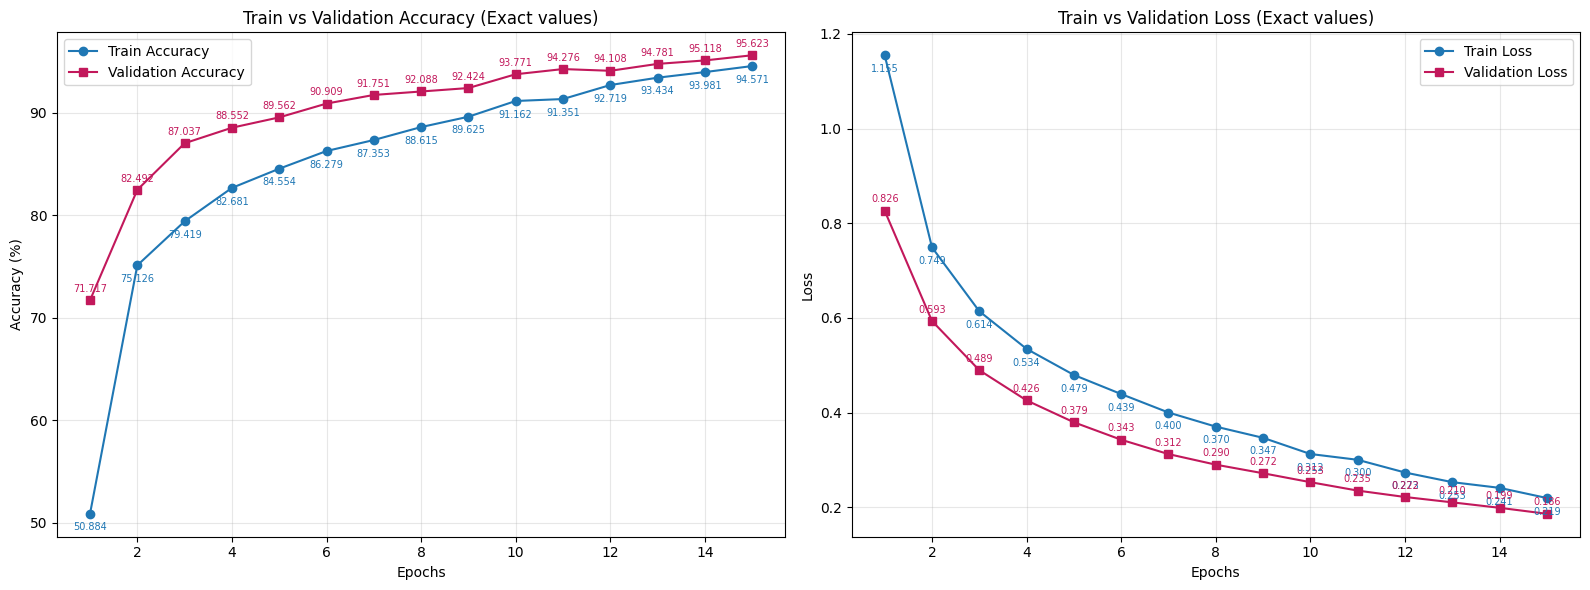

Best validation loss: 0.1862 at epoch 15
Best validation accuracy: 95.623% at epoch 15


In [22]:
tr_plot(history, start_epoch=0)

85/85 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step
Confusion Matrix
[[207   9   3   0]
 [  1 140   4   3]
 [  3   0  76   0]
 [  1   5   1 142]]

Classification Report
              precision    recall  f1-score   support

      glioma       0.98      0.95      0.96       219
  meningioma       0.91      0.95      0.93       148
    no_tumor       0.90      0.96      0.93        79
   pituitary       0.98      0.95      0.97       149

    accuracy                           0.95       595
   macro avg       0.94      0.95      0.95       595
weighted avg       0.95      0.95      0.95       595



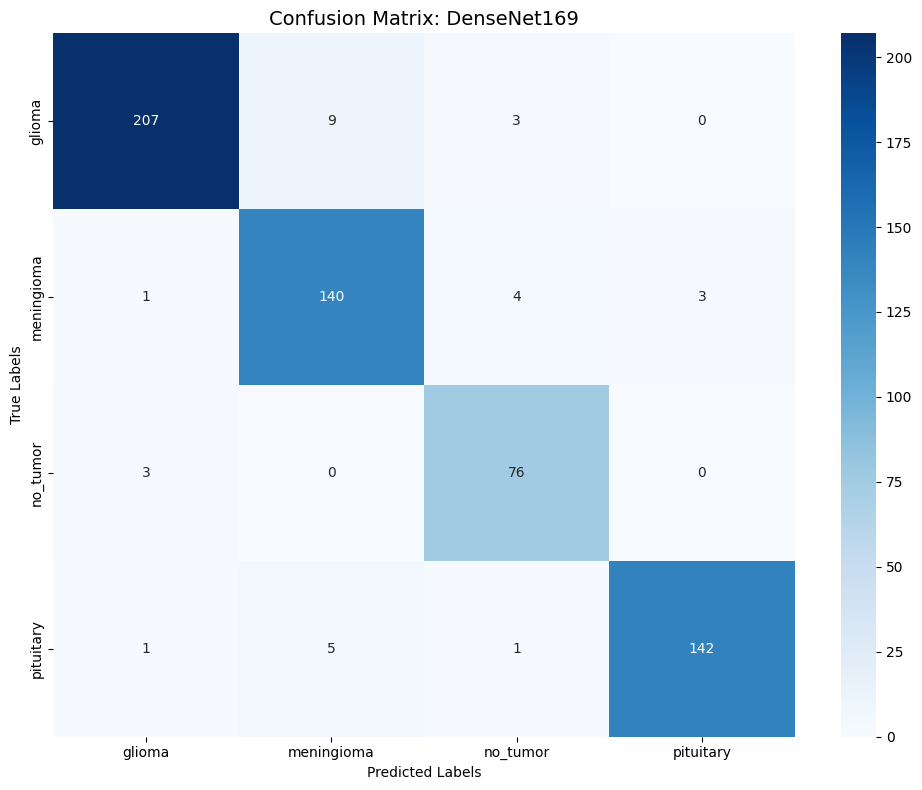

In [23]:
preds = model.predict(test_gen, verbose=1)

y_pred = np.argmax(preds, axis=1)

class_names = list(test_gen.class_indices.keys())

print('Confusion Matrix')

cm = confusion_matrix(test_labels, y_pred)

print(cm)

print('\nClassification Report')

print(
    classification_report(
        test_labels,
        y_pred,
        target_names=class_names
    )
)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)

plt.title('Confusion Matrix: DenseNet169', fontsize=14)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

plt.tight_layout()
plt.show()

# Parameters (Total & Trainable)

In [24]:
# Total Parameters
total_params = model.count_params()

# Trainable Parameters
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])

# Non-trainable Parameters
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)

Total Parameters: 12649540
Trainable Parameters: 982148
Non-Trainable Parameters: 11667392


# GMACs Calculation

In [25]:
!pip install keras-flops

In [26]:
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

# Create concrete function
full_model = tf.function(lambda x: model(x))
full_model = full_model.get_concrete_function(
    tf.TensorSpec([1, 224, 224, 3], tf.float32)
)

# Convert model to frozen graph
frozen_func = convert_variables_to_constants_v2(full_model)
graph_def = frozen_func.graph.as_graph_def()

# Calculate FLOPs
with tf.Graph().as_default() as graph:
    tf.graph_util.import_graph_def(graph_def, name='')

    run_meta = tf.compat.v1.RunMetadata()

    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

    flops = tf.compat.v1.profiler.profile(
        graph=graph,
        run_meta=run_meta,
        cmd='op',
        options=opts
    )

# Total FLOPs
total_flops = flops.total_float_ops

# Convert FLOPs → GMACs
gmacs = total_flops / 1e9 / 2

print(f"Total FLOPs: {total_flops:,}")
print(f"GMACs: {gmacs:.4f}")

I0000 00:00:1792041272.798255     166 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1792041272.798481     166 single_machine.cc:376] Starting new session
I0000 00:00:1792041272.814171     166 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792041272.815826     166 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation ker

# Latency

In [27]:
import time

# Take one batch
sample_batch = next(test_gen)[0]

# Single image
single_image = np.expand_dims(sample_batch[0], axis=0)

# Warmup
model.predict(single_image, verbose=0)

# Measure latency
start_time = time.time()

model.predict(single_image, verbose=0)

end_time = time.time()

latency = (end_time - start_time) * 1000

print(f"Latency: {latency:.2f} ms")

Latency: 108.11 ms


# Inference Time

In [28]:
start_time = time.time()

preds = model.predict(test_gen, verbose=1)

end_time = time.time()

inference_time = end_time - start_time

print(f"Inference Time: {inference_time:.2f} seconds")

85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step
Inference Time: 2.81 seconds


# Throughput (FPS)
• FPS = images processed per second

In [29]:
num_images = len(test_df)

fps = num_images / inference_time

print(f"Throughput (FPS): {fps:.2f}")

Throughput (FPS): 212.06


# MCC (Matthews Correlation Coefficient)

In [30]:
from sklearn.metrics import matthews_corrcoef

# Predictions
y_pred = np.argmax(preds, axis=1)

# True labels
y_true = test_gen.labels

# MCC Score
mcc = matthews_corrcoef(y_true, y_pred)

print(f"MCC: {mcc:.4f}")

MCC: 0.9307


# Specificity

In [31]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)

specificities = []

for i in range(len(cm)):
    
    TP = cm[i, i]
    
    FP = np.sum(cm[:, i]) - TP
    
    FN = np.sum(cm[i, :]) - TP
    
    TN = np.sum(cm) - (TP + FP + FN)
    
    specificity = TN / (TN + FP)
    
    specificities.append(specificity)

# Average specificity
avg_specificity = np.mean(specificities)

print(f"Specificity: {avg_specificity:.4f}")

Specificity: 0.9833


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


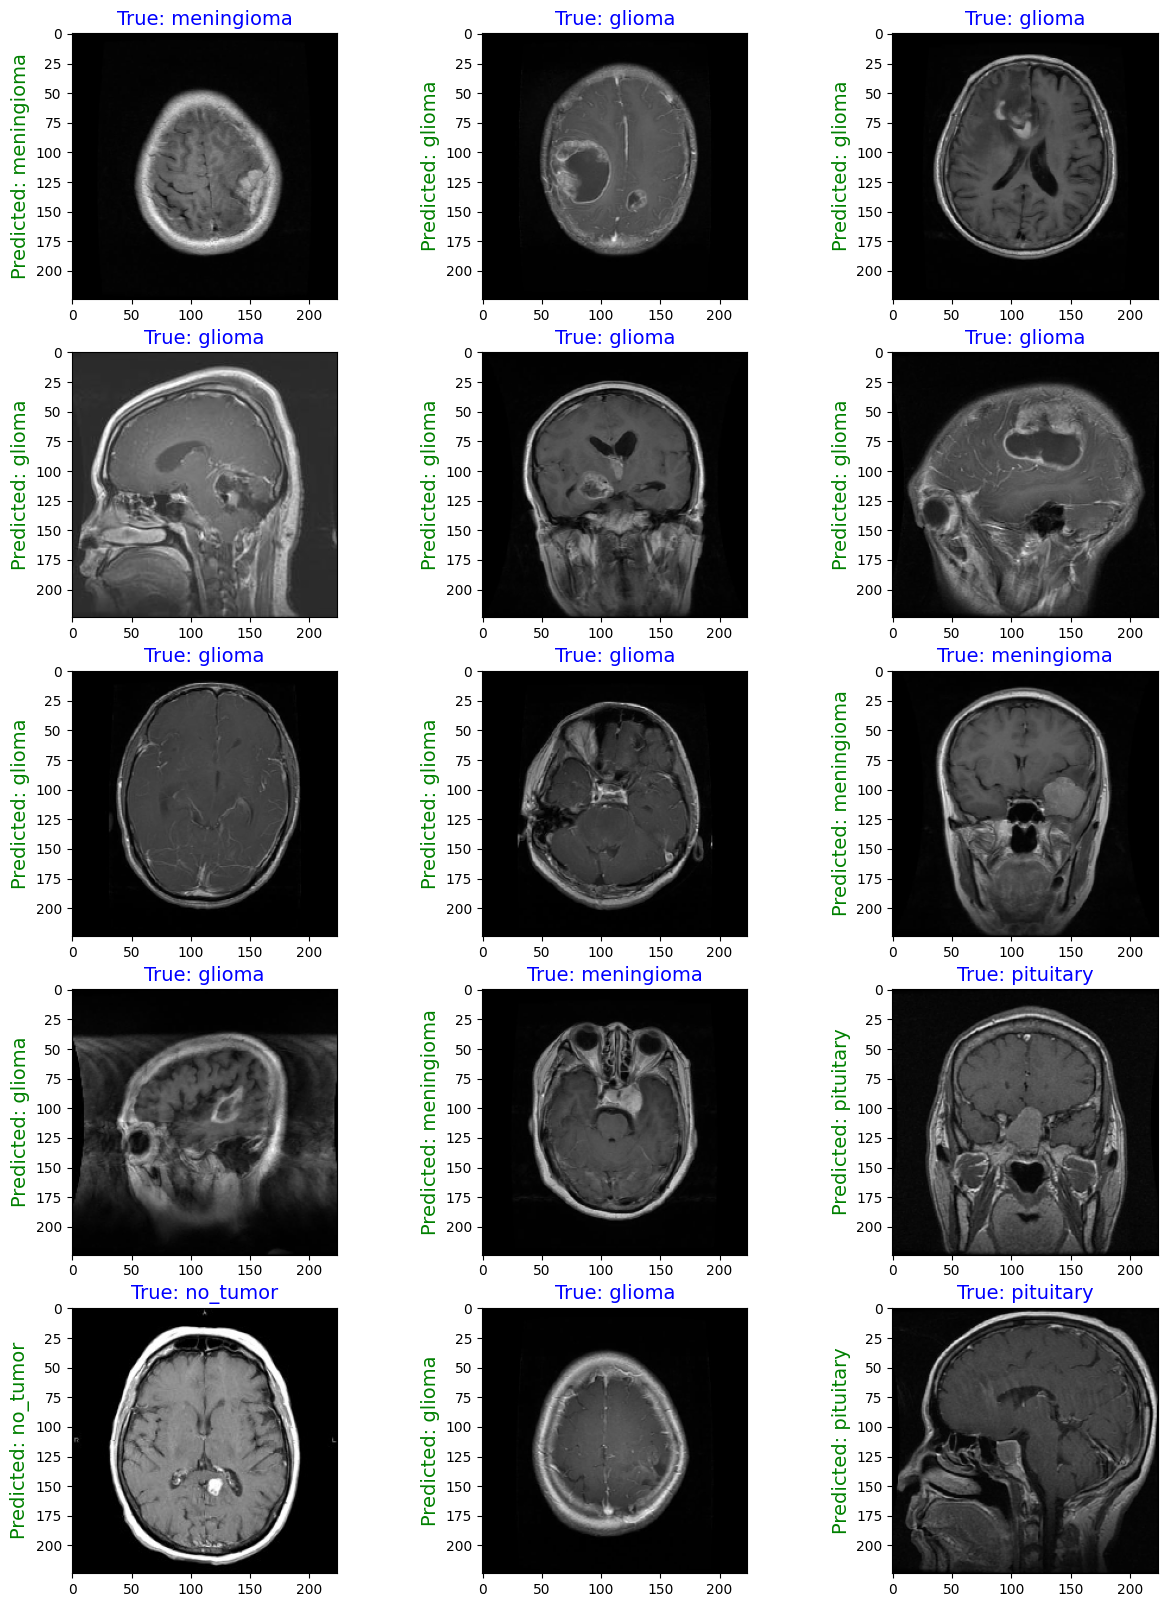

In [32]:
def print_images(gen):
    class_dict = gen.class_indices
    new_dict = {}
    # make a new dictionary with keys and values reversed
    for key, value in class_dict.items():
        new_dict[value] = key
    images, labels = next(gen)
    plt.figure(figsize=(15, 20))
    length = len(labels)
    if length < 15:
        r = length
    else:
        r = 15
    for i in range(r):
        plt.subplot(5, 3, i + 1)
        image = (images[i] + 1) / 2
        plt.imshow(image)
        index = np.argmax(labels[i])
        class_name = new_dict[index]
        pred = model.predict(np.expand_dims(images[i], axis=0))
        pred_index = np.argmax(pred)
        pred_class_name = new_dict[pred_index]
        plt.title(f"True: {class_name}", color='blue', fontsize=14) # Set true class title color to blue
        plt.ylabel(f"Predicted: {pred_class_name}", color='green', fontsize=14) # Set predicted class title color to green and moved it to xlabel for better visibility
        plt.axis('on')
    plt.show()

print_images(train_gen)